In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("data")

print("CSV faylları:")
for file in sorted(data_path.glob("*.csv")):
    print(file.name)

CSV faylları:
olist_customers_dataset.csv
olist_order_items_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [1]:
import sqlite3

conn = sqlite3.connect("ecommerce_kpi.db")

tables = conn.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
""").fetchall()

for table in tables:
    print(table[0])

category_translation
customers
order_items
orders
products
reviews
sellers
sqlite_sequence


In [2]:
table_names = [
    "orders",
    "order_items",
    "products",
    "reviews",
    "sellers",
    "customers",
    "category_translation"
]

for table in table_names:
    count = conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {count:,} rows")

orders: 99,441 rows
order_items: 112,650 rows
products: 32,951 rows
reviews: 99,224 rows
sellers: 3,095 rows
customers: 99,441 rows
category_translation: 71 rows


In [3]:
for table in table_names:
    print(f"\n--- {table} ---")

    columns = conn.execute(
        f"PRAGMA table_info('{table}')"
    ).fetchall()

    for col in columns:
        if col[5] > 0:
            print(f"Primary Key: {col[1]}")

    foreign_keys = conn.execute(
        f"PRAGMA foreign_key_list('{table}')"
    ).fetchall()

    if foreign_keys:
        for fk in foreign_keys:
            print(
                f"Foreign Key: {fk[3]} "
                f"-> {fk[2]}.{fk[4]}"
            )
    else:
        print("Foreign Key: yoxdur")


--- orders ---
Primary Key: order_id
Foreign Key: customer_id -> customers.customer_id

--- order_items ---
Primary Key: order_id
Primary Key: order_item_id
Foreign Key: seller_id -> sellers.seller_id
Foreign Key: product_id -> products.product_id
Foreign Key: order_id -> orders.order_id

--- products ---
Primary Key: product_id
Foreign Key: yoxdur

--- reviews ---
Primary Key: review_row_id
Foreign Key: order_id -> orders.order_id

--- sellers ---
Primary Key: seller_id
Foreign Key: yoxdur

--- customers ---
Primary Key: customer_id
Foreign Key: yoxdur

--- category_translation ---
Primary Key: product_category_name
Foreign Key: yoxdur


In [4]:
print("Ümumi sətir sayı:")
print(conn.execute("""
    SELECT COUNT(*) FROM order_items
""").fetchone()[0])

print("\nTəkrarlanan order_id + order_item_id cütləri:")
print(conn.execute("""
    SELECT COUNT(*)
    FROM (
        SELECT order_id, order_item_id
        FROM order_items
        GROUP BY order_id, order_item_id
        HAVING COUNT(*) > 1
    )
""").fetchone()[0])

print("\nTəkrarlanan order_item_id dəyərləri:")
print(conn.execute("""
    SELECT COUNT(*)
    FROM (
        SELECT order_item_id
        FROM order_items
        GROUP BY order_item_id
        HAVING COUNT(*) > 1
    )
""").fetchone()[0])


Ümumi sətir sayı:
112650

Təkrarlanan order_id + order_item_id cütləri:
0

Təkrarlanan order_item_id dəyərləri:
20


In [5]:
tables_to_check = [
    "orders",
    "order_items",
    "products",
    "reviews",
    "sellers",
    "customers",
    "category_translation"
]

for table in tables_to_check:
    result = conn.execute(
        f"PRAGMA foreign_key_check('{table}')"
    ).fetchall()

    print(f"{table}: {len(result)} pozuntu")

orders: 0 pozuntu
order_items: 0 pozuntu
products: 0 pozuntu
reviews: 0 pozuntu
sellers: 0 pozuntu
customers: 0 pozuntu
category_translation: 0 pozuntu


In [6]:
with open("queries.sql", "r", encoding="utf-8") as f:
    sql_text = f.read()

print(sql_text)


-- 1. Customers: hər müştəri üçün unikal customer_id
CREATE TABLE IF NOT EXISTS customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    customer_state TEXT
);

-- 2. Orders: hər sifariş üçün unikal order_id
CREATE TABLE IF NOT EXISTS orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_status TEXT,
    order_purchase_timestamp TEXT,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT,
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

-- 3. Sellers: hər satıcı üçün unikal seller_id
CREATE TABLE IF NOT EXISTS sellers (
    seller_id TEXT PRIMARY KEY,
    seller_zip_code_prefix TEXT,
    seller_city TEXT,
    seller_state TEXT
);

-- 4. Product category translations
CREATE TABLE IF NOT EXISTS category_translation (
    product_category_name TEXT PRIMARY KEY,
    product

In [7]:
result = conn.execute("""
    SELECT
        COUNT(*) AS total_order_items,
        COUNT(DISTINCT order_id) AS unique_orders,
        ROUND(
            1.0 * COUNT(*) / COUNT(DISTINCT order_id),
            2
        ) AS avg_items_per_order
    FROM order_items;
""").fetchone()

print("Order items:", result[0])
print("Unique orders:", result[1])
print("Average items per order:", result[2])

Order items: 112650
Unique orders: 98666
Average items per order: 1.14


In [8]:
tables = [
    "orders",
    "order_items",
    "products",
    "reviews",
    "sellers",
    "customers",
    "category_translation"
]

for table in tables:
    count = conn.execute(
        f"SELECT COUNT(*) FROM {table}"
    ).fetchone()[0]

    print(f"{table}: {count}")

orders: 99441
order_items: 112650
products: 32951
reviews: 99224
sellers: 3095
customers: 99441
category_translation: 71


In [9]:
result = conn.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT order_id) AS unique_orders,
        COUNT(DISTINCT product_id) AS unique_products,
        COUNT(DISTINCT seller_id) AS unique_sellers
    FROM analytical_base;
""").fetchone()

print("Total rows:", result[0])
print("Unique orders:", result[1])
print("Unique products:", result[2])
print("Unique sellers:", result[3])

Total rows: 112650
Unique orders: 98666
Unique products: 32951
Unique sellers: 3095


In [10]:
result = conn.execute("""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT order_id) AS unique_orders,
        SUM(
            CASE
                WHEN order_status = 'delivered' THEN 1
                ELSE 0
            END
        ) AS delivered_rows,
        SUM(
            CASE
                WHEN order_status <> 'delivered' THEN 1
                ELSE 0
            END
        ) AS non_delivered_rows
    FROM analytical_base;
""").fetchone()

print("Total rows:", result[0])
print("Unique orders:", result[1])
print("Delivered rows:", result[2])
print("Non-delivered rows:", result[3])

Total rows: 112650
Unique orders: 98666
Delivered rows: 110197
Non-delivered rows: 2453


In [11]:
for row in conn.execute("""
    SELECT type, name, sql
    FROM sqlite_master
    WHERE name = 'analytical_base';
""").fetchall():
    print("Object type:", row[0])
    print("Object name:", row[1])
    print("SQL definition:")
    print(row[2])

Object type: view
Object name: analytical_base
SQL definition:
CREATE VIEW analytical_base AS
        WITH review_per_order AS (
            SELECT
                order_id,
                AVG(review_score) AS review_score,
                COUNT(*) AS review_count
            FROM reviews
            GROUP BY order_id
        )
        SELECT
            o.order_id,
            o.customer_id,
            o.order_status,
            o.order_purchase_timestamp,
            o.order_delivered_customer_date,
            o.order_estimated_delivery_date,
            oi.order_item_id,
            oi.product_id,
            oi.seller_id,
            oi.price,
            oi.freight_value,
            p.product_category_name,
            ct.product_category_name_english,
            r.review_score,
            r.review_count
        FROM orders o
        INNER JOIN order_items oi
            ON o.order_id = oi.order_id
        INNER JOIN products p
            ON oi.product_id = p.product_id
  

In [12]:
result = conn.execute("""
    SELECT
        (SELECT ROUND(SUM(price), 2)
         FROM order_items) AS direct_revenue,

        (SELECT ROUND(SUM(price), 2)
         FROM analytical_base) AS joined_revenue,

        (SELECT ROUND(SUM(price), 2)
         FROM analytical_base)
        -
        (SELECT ROUND(SUM(price), 2)
         FROM order_items) AS revenue_difference;
""").fetchone()

print("Direct revenue:", result[0])
print("Joined revenue:", result[1])
print("Revenue difference:", result[2])

Direct revenue: 13591643.7
Joined revenue: 13591643.7
Revenue difference: 0.0


In [13]:
result = conn.execute("""
    WITH order_revenue AS (
        SELECT
            order_id,
            SUM(price) AS revenue
        FROM analytical_base
        WHERE order_status = 'delivered'
        GROUP BY order_id
    ),
    delivery AS (
        SELECT
            order_id,
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp) AS delivery_days
        FROM orders
        WHERE order_status = 'delivered'
          AND order_delivered_customer_date IS NOT NULL
          AND order_purchase_timestamp IS NOT NULL
    ),
    review_per_order AS (
        SELECT
            order_id,
            AVG(review_score) AS review_score
        FROM reviews
        GROUP BY order_id
    )
    SELECT
        ROUND(SUM(orv.revenue), 2) AS total_revenue,
        ROUND(AVG(orv.revenue), 2) AS average_order_value,
        ROUND(AVG(d.delivery_days), 2) AS avg_delivery_days,
        ROUND(AVG(r.review_score), 2) AS avg_review_score
    FROM order_revenue orv
    LEFT JOIN delivery d ON orv.order_id = d.order_id
    LEFT JOIN review_per_order r ON orv.order_id = r.order_id;
""").fetchone()

print("Total revenue:", result[0])
print("Average order value:", result[1])
print("Average delivery days:", result[2])
print("Average review score:", result[3])

Total revenue: 13221498.11
Average order value: 137.04
Average delivery days: 12.56
Average review score: 4.16


In [14]:
result = conn.execute("""
    SELECT
        COUNT(*) AS delivered_orders,
        ROUND(SUM(order_revenue), 2) AS total_revenue,
        ROUND(AVG(order_revenue), 2) AS average_order_value
    FROM (
        SELECT
            order_id,
            SUM(price) AS order_revenue
        FROM analytical_base
        WHERE order_status = 'delivered'
        GROUP BY order_id
    );
""").fetchone()

print("Delivered orders:", result[0])
print("Total revenue:", result[1])
print("Average order value:", result[2])

Delivered orders: 96478
Total revenue: 13221498.11
Average order value: 137.04


In [17]:
category_kpis = conn.execute("""
SELECT
    COALESCE(ab.product_category_name_english, 'unknown') AS category,
    ROUND(SUM(ab.price), 2) AS total_revenue,
    ROUND(
        SUM(ab.price) * 1.0 / COUNT(DISTINCT ab.order_id),
        2
    ) AS avg_order_value,
    ROUND(
        AVG(
            julianday(ab.order_delivered_customer_date)
            - julianday(ab.order_purchase_timestamp)
        ),
        2
    ) AS avg_delivery_days,
    ROUND(AVG(ab.review_score), 2) AS avg_review_score
FROM analytical_base ab
WHERE ab.order_status = 'delivered'
GROUP BY COALESCE(ab.product_category_name_english, 'unknown')
ORDER BY total_revenue DESC
""").fetchall()

for row in category_kpis[:10]:
    print(row)

print("Total categories:", len(category_kpis))

('health_beauty', 1233131.72, 142.61, 11.98, 4.19)
('watches_gifts', 1166176.98, 212.23, 12.66, 4.07)
('bed_bath_table', 1023434.76, 110.38, 12.81, 3.92)
('sports_leisure', 954852.55, 126.81, 12.15, 4.17)
('computers_accessories', 888724.61, 136.1, 13.23, 3.99)
('furniture_decor', 711927.69, 112.88, 12.88, 3.95)
('housewares', 615628.69, 107.2, 10.92, 4.11)
('cool_stuff', 610204.1, 171.45, 12.36, 4.19)
('auto', 578966.65, 151.96, 12.23, 4.12)
('toys', 471286.48, 123.89, 11.7, 4.21)
Total categories: 72


In [18]:
monthly_kpis = conn.execute("""
WITH order_revenue AS (
    SELECT
        order_id,
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        SUM(price) AS revenue
    FROM analytical_base
    WHERE order_status = 'delivered'
    GROUP BY order_id, month
),
order_delivery AS (
    SELECT
        order_id,
        AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        ) AS delivery_days
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
    GROUP BY order_id
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    rev.month,
    ROUND(SUM(rev.revenue), 2) AS total_revenue,
    ROUND(AVG(rev.revenue), 2) AS avg_order_value,
    ROUND(AVG(del.delivery_days), 2) AS avg_delivery_days,
    ROUND(AVG(r.review_score), 2) AS avg_review_score
FROM order_revenue rev
LEFT JOIN order_delivery del ON rev.order_id = del.order_id
LEFT JOIN order_reviews r ON rev.order_id = r.order_id
GROUP BY rev.month
ORDER BY rev.month;
""").fetchall()

for row in monthly_kpis:
    print(row)

print("Total months:", len(monthly_kpis))

('2016-09', 134.97, 134.97, 54.81, 1.0)
('2016-10', 40325.11, 152.17, 19.6, 4.01)
('2016-12', 10.9, 10.9, 4.69, 5.0)
('2017-01', 111798.36, 149.06, 12.65, 4.2)
('2017-02', 234223.4, 141.7, 13.17, 4.2)
('2017-03', 359198.85, 141.08, 12.95, 4.19)
('2017-04', 340669.68, 147.92, 14.92, 4.14)
('2017-05', 489338.25, 138.0, 11.32, 4.24)
('2017-06', 421923.37, 134.58, 12.01, 4.22)
('2017-07', 481604.52, 124.38, 11.59, 4.26)
('2017-08', 554699.7, 132.29, 11.15, 4.31)
('2017-09', 607399.67, 146.36, 11.85, 4.27)
('2017-10', 648247.65, 144.76, 11.86, 4.21)
('2017-11', 987765.37, 135.51, 15.16, 3.99)
('2017-12', 726033.19, 131.69, 15.39, 4.09)
('2018-01', 924645.0, 130.8, 14.08, 4.11)
('2018-02', 826437.13, 126.08, 16.95, 3.88)
('2018-03', 953356.25, 136.14, 16.3, 3.81)
('2018-04', 973534.09, 143.21, 11.5, 4.21)
('2018-05', 977544.69, 144.84, 11.42, 4.24)
('2018-06', 856077.86, 140.36, 9.24, 4.31)
('2018-07', 867953.46, 140.92, 8.96, 4.32)
('2018-08', 838576.64, 132.04, 7.73, 4.31)
Total months: 23

In [19]:
category_revenue = conn.execute("""
SELECT
    COALESCE(product_category_name_english, 'unknown') AS category,
    ROUND(SUM(price), 2) AS total_revenue
FROM analytical_base
WHERE order_status = 'delivered'
GROUP BY COALESCE(product_category_name_english, 'unknown')
""").fetchall()

category_revenue = sorted(
    category_revenue,
    key=lambda row: row[1],
    reverse=True
)

print("TOP 5 CATEGORIES BY REVENUE")
for row in category_revenue[:5]:
    print(row)

print("\nBOTTOM 5 CATEGORIES BY REVENUE")
for row in category_revenue[-5:]:
    print(row)

TOP 5 CATEGORIES BY REVENUE
('health_beauty', 1233131.72)
('watches_gifts', 1166176.98)
('bed_bath_table', 1023434.76)
('sports_leisure', 954852.55)
('computers_accessories', 888724.61)

BOTTOM 5 CATEGORIES BY REVENUE
('flowers', 1110.04)
('home_comfort_2', 760.27)
('cds_dvds_musicals', 730.0)
('fashion_childrens_clothes', 519.95)
('security_and_services', 283.29)


In [20]:
review_categories = conn.execute("""
WITH order_category_reviews AS (
    SELECT DISTINCT
        ab.order_id,
        COALESCE(
            ab.product_category_name_english,
            'unknown'
        ) AS category,
        r.review_score
    FROM analytical_base ab
    JOIN reviews r
        ON ab.order_id = r.order_id
    WHERE ab.order_status = 'delivered'
)
SELECT
    category,
    ROUND(AVG(review_score), 2) AS avg_review_score,
    COUNT(DISTINCT order_id) AS order_count
FROM order_category_reviews
GROUP BY category
HAVING COUNT(DISTINCT order_id) >= 100
ORDER BY avg_review_score DESC
""").fetchall()

print("TOP 5 CATEGORIES BY REVIEW SCORE")
for row in review_categories[:5]:
    print(row)

print("\nBOTTOM 5 CATEGORIES BY REVIEW SCORE")
for row in sorted(review_categories, key=lambda row: row[1])[:5]:
    print(row)

print("Eligible categories:", len(review_categories))

TOP 5 CATEGORIES BY REVIEW SCORE
('books_general_interest', 4.53, 492)
('food_drink', 4.45, 221)
('books_technical', 4.43, 255)
('luggage_accessories', 4.37, 1015)
('food', 4.33, 437)

BOTTOM 5 CATEGORIES BY REVIEW SCORE
('office_furniture', 3.64, 1244)
('fashion_male_clothing', 3.82, 105)
('audio', 3.83, 345)
('home_confort', 3.88, 390)
('fixed_telephony', 3.97, 209)
Eligible categories: 52


In [21]:
seller_kpis = conn.execute("""
WITH seller_revenue AS (
    SELECT
        seller_id,
        SUM(price) AS revenue,
        COUNT(DISTINCT order_id) AS order_count
    FROM analytical_base
    WHERE order_status = 'delivered'
    GROUP BY seller_id
),
seller_delivery AS (
    SELECT
        ab.seller_id,
        AVG(
            julianday(ab.order_delivered_customer_date)
            - julianday(ab.order_purchase_timestamp)
        ) AS avg_delivery_days
    FROM analytical_base ab
    WHERE ab.order_status = 'delivered'
      AND ab.order_delivered_customer_date IS NOT NULL
      AND ab.order_purchase_timestamp IS NOT NULL
    GROUP BY ab.seller_id
),
seller_reviews AS (
    SELECT
        ab.seller_id,
        AVG(r.review_score) AS avg_review_score
    FROM (
        SELECT DISTINCT seller_id, order_id
        FROM analytical_base
        WHERE order_status = 'delivered'
    ) ab
    JOIN reviews r ON ab.order_id = r.order_id
    GROUP BY ab.seller_id
)
SELECT
    sr.seller_id,
    ROUND(sr.revenue, 2) AS revenue,
    sr.order_count,
    ROUND(srev.avg_review_score, 2) AS avg_review_score,
    ROUND(sd.avg_delivery_days, 2) AS avg_delivery_days,
    RANK() OVER (ORDER BY sr.revenue DESC) AS revenue_rank
FROM seller_revenue sr
LEFT JOIN seller_reviews srev
    ON sr.seller_id = srev.seller_id
LEFT JOIN seller_delivery sd
    ON sr.seller_id = sd.seller_id
ORDER BY revenue_rank
""").fetchall()

print("Top 10 sellers by revenue:")
for row in seller_kpis[:10]:
    print(row)

print("Total sellers with delivered sales:", len(seller_kpis))

Top 10 sellers by revenue:
('4869f7a5dfa277a7dca6462dcf3b52b2', 226987.93, 1124, 4.15, 15.01, 1)
('53243585a1d6dc2643021fd1853d8905', 217940.44, 348, 4.19, 13.37, 2)
('4a3ca9315b744ce9f8e9374361493884', 196882.12, 1772, 3.85, 14.42, 3)
('fa1c13f2614d7b5c4749cbc52fecda94', 190917.14, 578, 4.37, 13.34, 4)
('7c67e1448b00f6e969d365cea6b010ab', 186570.05, 973, 3.5, 22.39, 5)
('7e93a43ef30c4f03f38b393420bc753a', 165981.49, 319, 4.36, 11.34, 6)
('da8622b14eb17ae2831f4ac5b9dab84a', 159816.87, 1311, 4.18, 11.17, 7)
('7a67c85e85bb2ce8582c35f2203ad736', 139658.69, 1145, 4.28, 11.17, 8)
('1025f0e2d44d7041d6cf58b6550e0bfa', 138208.56, 910, 4.01, 12.05, 9)
('955fee9216a65b617aa5c0531780ce60', 131836.71, 1261, 4.2, 10.74, 10)
Total sellers with delivered sales: 2970


In [22]:
import pandas as pd

q10_df = pd.read_sql_query("""
WITH order_category AS (
    SELECT DISTINCT
        order_id,
        COALESCE(
            product_category_name_english,
            'unknown'
        ) AS category,
        order_purchase_timestamp,
        order_delivered_customer_date
    FROM analytical_base
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    oc.category,
    AVG(
        julianday(oc.order_delivered_customer_date)
        - julianday(oc.order_purchase_timestamp)
    ) AS avg_delivery_days,
    AVG(r.review_score) AS avg_review_score,
    COUNT(DISTINCT oc.order_id) AS order_count
FROM order_category oc
LEFT JOIN order_reviews r
    ON oc.order_id = r.order_id
GROUP BY oc.category
HAVING COUNT(DISTINCT oc.order_id) >= 100
ORDER BY oc.category
""", conn)

print(q10_df.head(10))
print("Number of categories:", len(q10_df))

                     category  avg_delivery_days  avg_review_score  \
0  agro_industry_and_commerce          11.432300          4.107345   
1            air_conditioning          11.881089          4.115702   
2                         art          11.258496          4.098446   
3                       audio          13.470062          3.839130   
4                        auto          12.330584          4.145608   
5                        baby          12.676481          4.103516   
6              bed_bath_table          12.990189          3.999292   
7      books_general_interest          11.530295          4.533605   
8             books_technical          10.634351          4.427451   
9          christmas_supplies          15.374882          4.113821   

   order_count  
0          177  
1          246  
2          195  
3          348  
4         3809  
5         2809  
6         9272  
7          495  
8          256  
9          125  
Number of categories: 52


In [23]:
correlation = q10_df[
    ["avg_delivery_days", "avg_review_score"]
].corr().iloc[0, 1]

print("Correlation coefficient:", round(correlation, 4))

if correlation < -0.3:
    print("Interpretation: Longer delivery times are associated with lower review scores.")
elif correlation > 0.3:
    print("Interpretation: Longer delivery times are associated with higher review scores.")
else:
    print("Interpretation: The relationship is weak or close to zero.")

Correlation coefficient: -0.5756
Interpretation: Longer delivery times are associated with lower review scores.


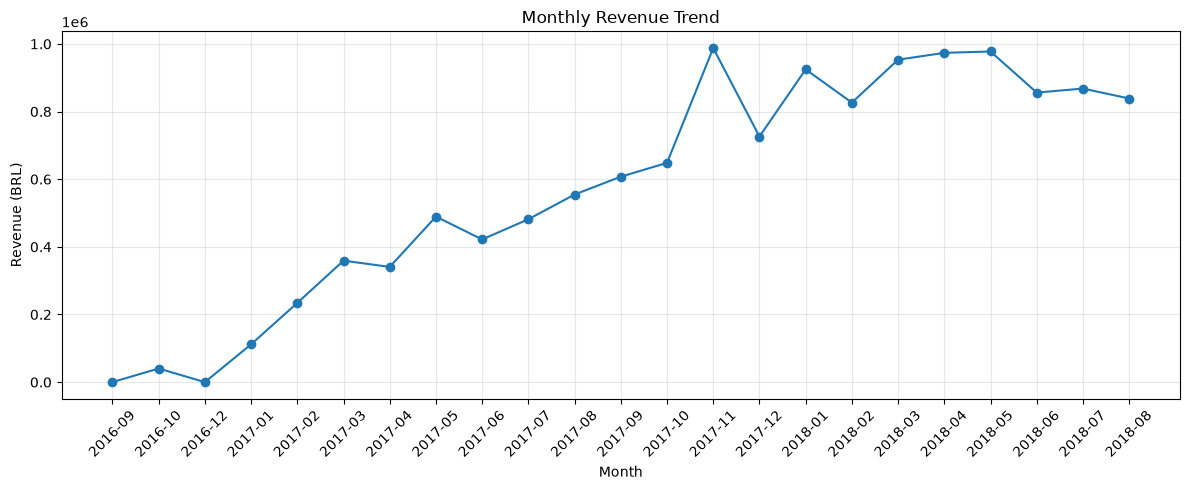

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

monthly_df = pd.DataFrame(
    monthly_kpis,
    columns=[
        "month",
        "total_revenue",
        "avg_order_value",
        "avg_delivery_days",
        "avg_review_score"
    ]
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_df["month"],
    monthly_df["total_revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

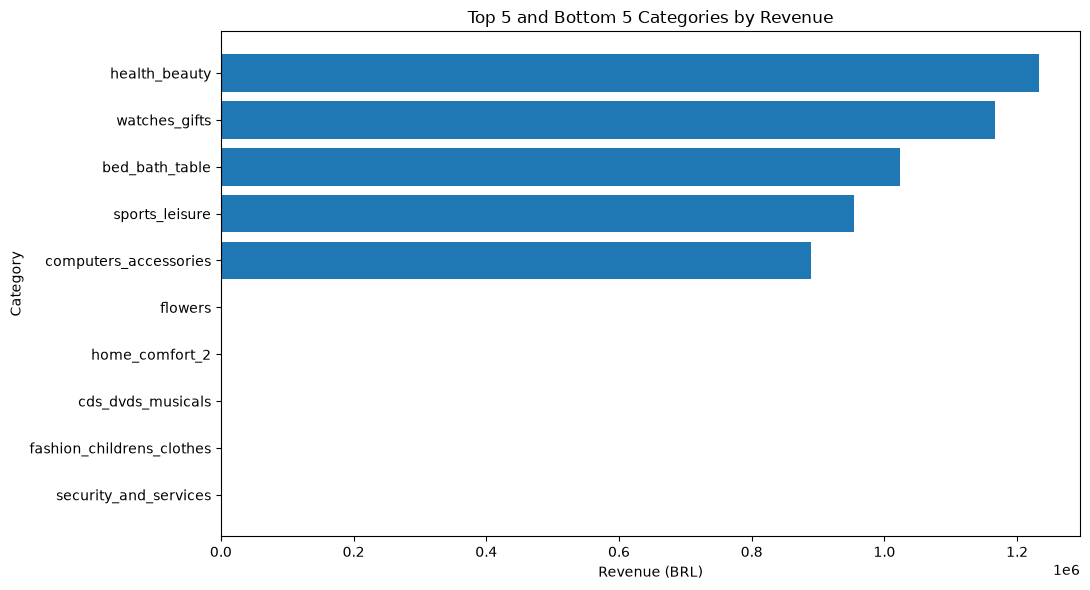

In [25]:
top5 = category_revenue[:5]
bottom5 = sorted(category_revenue, key=lambda row: row[1])[:5]

chart_df = pd.DataFrame(
    top5 + bottom5,
    columns=["category", "total_revenue"]
)

chart_df = chart_df.sort_values("total_revenue")

plt.figure(figsize=(11, 6))
plt.barh(chart_df["category"], chart_df["total_revenue"])
plt.title("Top 5 and Bottom 5 Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

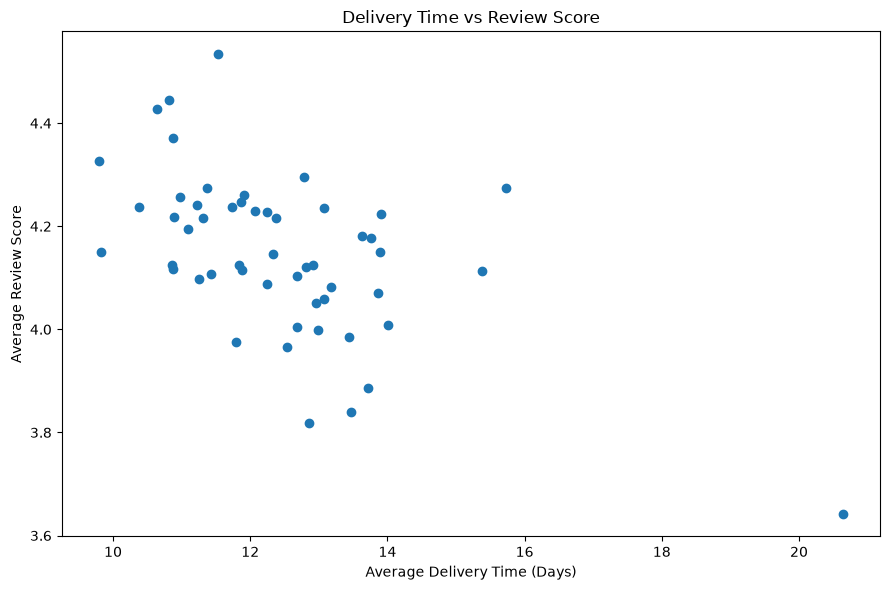

In [26]:
plt.figure(figsize=(9, 6))

plt.scatter(
    q10_df["avg_delivery_days"],
    q10_df["avg_review_score"]
)

plt.title("Delivery Time vs Review Score")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Average Review Score")
plt.tight_layout()
plt.show()

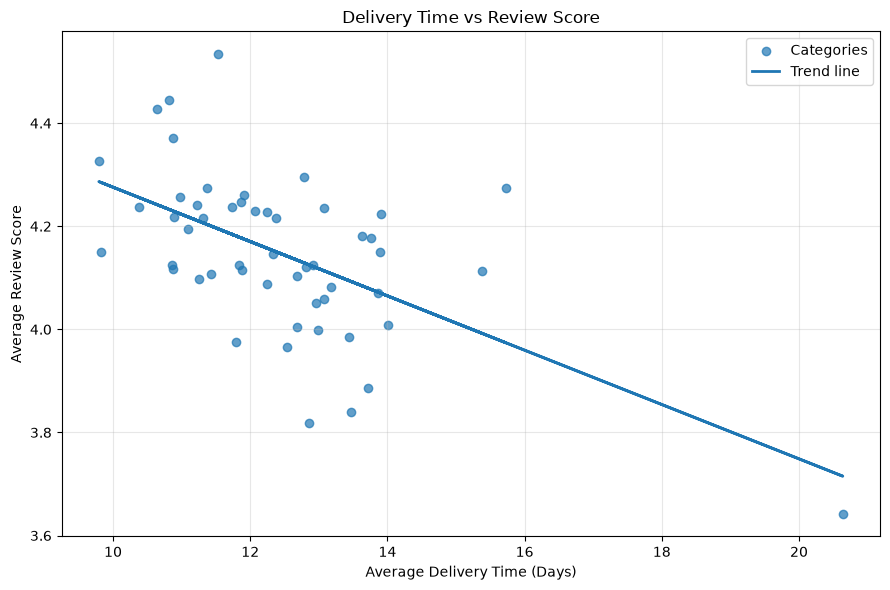

In [27]:
import numpy as np
import matplotlib.pyplot as plt

x = q10_df["avg_delivery_days"]
y = q10_df["avg_review_score"]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(9, 6))
plt.scatter(x, y, alpha=0.7, label="Categories")

plt.plot(
    x,
    slope * x + intercept,
    linewidth=2,
    label="Trend line"
)

plt.title("Delivery Time vs Review Score")
plt.xlabel("Average Delivery Time (Days)")
plt.ylabel("Average Review Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
print("Correlation:", round(correlation, 4))

print("\nHighest revenue category:")
print(max(category_revenue, key=lambda row: row[1]))

print("\nLowest revenue category:")
print(min(category_revenue, key=lambda row: row[1]))

print("\nHighest review score category:")
print(max(review_categories, key=lambda row: row[1]))

print("\nLowest review score category:")
print(min(review_categories, key=lambda row: row[1]))

Correlation: -0.5756

Highest revenue category:
('health_beauty', 1233131.72)

Lowest revenue category:
('security_and_services', 283.29)

Highest review score category:
('books_general_interest', 4.53, 492)

Lowest review score category:
('office_furniture', 3.64, 1244)


In [2]:

import pandas as pd

files = {
    "orders": "data/olist_orders_dataset.csv",
    "order_items": "data/olist_order_items_dataset.csv",
    "products": "data/olist_products_dataset.csv",
    "reviews": "data/olist_order_reviews_dataset.csv",
    "sellers": "data/olist_sellers_dataset.csv",
    "customers": "data/olist_customers_dataset.csv",
    "category_translation": "data/product_category_name_translation.csv"
}

for name, path in files.items():
    df = pd.read_csv(path)
    print(f"\n{name.upper()} — sətir sayı: {df.shape[0]}, sütun sayı: {df.shape[1]}")
    print("Sütunlar:", df.columns.tolist())



ORDERS — sətir sayı: 99441, sütun sayı: 8
Sütunlar: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER_ITEMS — sətir sayı: 112650, sütun sayı: 7
Sütunlar: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

PRODUCTS — sətir sayı: 32951, sütun sayı: 9
Sütunlar: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

REVIEWS — sətir sayı: 99224, sütun sayı: 7
Sütunlar: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

SELLERS — sətir sayı: 3095, sütun sayı: 4
Sütunlar: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

CUSTOMERS — sətir

In [3]:
checks = {
    "orders": ("data/olist_orders_dataset.csv", ["order_id"]),
    "order_items": ("data/olist_order_items_dataset.csv", ["order_id", "order_item_id"]),
    "products": ("data/olist_products_dataset.csv", ["product_id"]),
    "reviews": ("data/olist_order_reviews_dataset.csv", ["review_id"]),
    "sellers": ("data/olist_sellers_dataset.csv", ["seller_id"]),
    "customers": ("data/olist_customers_dataset.csv", ["customer_id"]),
    "category_translation": (
        "data/product_category_name_translation.csv",
        ["product_category_name"]
    )
}

for table, (path, keys) in checks.items():
    df = pd.read_csv(path)
    duplicate_count = df.duplicated(subset=keys).sum()
    null_count = df[keys].isna().any(axis=1).sum()

    print(f"{table}:")
    print(f"  Təkrarlanan açar sətirləri: {duplicate_count}")
    print(f"  Açarı boş olan sətirlər: {null_count}")

orders:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
order_items:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
products:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
reviews:
  Təkrarlanan açar sətirləri: 814
  Açarı boş olan sətirlər: 0
sellers:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
customers:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0
category_translation:
  Təkrarlanan açar sətirləri: 0
  Açarı boş olan sətirlər: 0


In [4]:

%%writefile queries.sql

-- 1. Customers: hər müştəri üçün unikal customer_id
CREATE TABLE IF NOT EXISTS customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    customer_state TEXT
);

-- 2. Orders: hər sifariş üçün unikal order_id
CREATE TABLE IF NOT EXISTS orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_status TEXT,
    order_purchase_timestamp TEXT,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT,
    FOREIGN KEY (customer_id) REFERENCES customers(customer_id)
);

-- 3. Sellers: hər satıcı üçün unikal seller_id
CREATE TABLE IF NOT EXISTS sellers (
    seller_id TEXT PRIMARY KEY,
    seller_zip_code_prefix TEXT,
    seller_city TEXT,
    seller_state TEXT
);

-- 4. Product category translations
CREATE TABLE IF NOT EXISTS category_translation (
    product_category_name TEXT PRIMARY KEY,
    product_category_name_english TEXT
);

-- 5. Products: hər məhsul üçün unikal product_id
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL,
    FOREIGN KEY (product_category_name)
        REFERENCES category_translation(product_category_name)
);

-- 6. Order items: bir sifarişdə bir neçə məhsul ola bilər
CREATE TABLE IF NOT EXISTS order_items (
    order_id TEXT NOT NULL,
    order_item_id INTEGER NOT NULL,
    product_id TEXT NOT NULL,
    seller_id TEXT NOT NULL,
    shipping_limit_date TEXT,
    price REAL,
    freight_value REAL,
    PRIMARY KEY (order_id, order_item_id),
    FOREIGN KEY (order_id) REFERENCES orders(order_id),
    FOREIGN KEY (product_id) REFERENCES products(product_id),
    FOREIGN KEY (seller_id) REFERENCES sellers(seller_id)
);

-- 7. Reviews: review_id təkrarlandığı üçün texniki ID istifadə edirik
CREATE TABLE IF NOT EXISTS reviews (
    review_row_id INTEGER PRIMARY KEY AUTOINCREMENT,
    review_id TEXT,
    order_id TEXT NOT NULL,
    review_score INTEGER,
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT,
    FOREIGN KEY (order_id) REFERENCES orders(order_id)
);


Overwriting queries.sql


In [5]:
from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

sql_text = sql_text.replace(
    """    FOREIGN KEY (product_category_name)
        REFERENCES category_translation(product_category_name)
""",
    ""
)

sql_path.write_text(sql_text, encoding="utf-8")

print("Kateqoriya əlaqəsi düzəldildi.")

Kateqoriya əlaqəsi düzəldildi.


In [6]:

import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")


OperationalError: near ")": syntax error

In [ ]:
for number, line in enumerate(
    Path("queries.sql").read_text(encoding="utf-8").splitlines(),
    start=1
):
    print(f"{number}: {line}")

In [ ]:
sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

sql_text = sql_text.replace(
    "product_width_cm REAL,\n);",
    "product_width_cm REAL\n);"
)

sql_path.write_text(sql_text, encoding="utf-8")

print("Vergül düzəldildi.")

In [ ]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(
        Path("queries.sql").read_text(encoding="utf-8")
    )

print("SQL cədvəlləri uğurla yaradıldı.")

In [ ]:
with sqlite3.connect("ecommerce_kpi.db") as conn:
    tables = pd.read_sql_query(
        """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table'
        ORDER BY name;
        """,
        conn
    )

display(tables)

In [ ]:

import csv
import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
data_path = Path("data")

table_files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "products": "olist_products_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv"
}

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    for table, filename in table_files.items():
        file_path = data_path / filename

        with open(file_path, "r", encoding="utf-8-sig", newline="") as file:
            reader = csv.DictReader(file)
            columns = reader.fieldnames

            placeholders = ", ".join(["?"] * len(columns))
            column_names = ", ".join(f'"{col}"' for col in columns)

            # Reviews cədvəlində texniki ID avtomatik yaranır.
            if table == "reviews":
                column_names = ", ".join(f'"{col}"' for col in columns)

            insert_sql = (
                f'INSERT INTO "{table}" ({column_names}) '
                f'VALUES ({placeholders})'
            )

            rows = (
                [row[col] if row[col] != "" else None for col in columns]
                for row in reader
            )

            conn.executemany(insert_sql, rows)

        print(f"{table}: məlumatlar yükləndi.")

print("Bütün CSV məlumatları bazaya yükləndi.")


In [ ]:

expected_tables = [
    "customers",
    "orders",
    "sellers",
    "category_translation",
    "products",
    "order_items",
    "reviews"
]

with sqlite3.connect("ecommerce_kpi.db") as conn:
    for table in expected_tables:
        count = pd.read_sql_query(
            f'SELECT COUNT(*) AS total_rows FROM "{table}"',
            conn
        ).iloc[0]["total_rows"]

        print(f"{table}: {count:,} sətir")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")

    for table in [
        "orders",
        "order_items",
        "products",
        "reviews"
    ]:
        result = conn.execute(
            f'PRAGMA foreign_key_list("{table}")'
        ).fetchall()

        print(f"\n{table.upper()} — Foreign Keys:")
        for row in result:
            print(f"  {row[3]} -> {row[2]}.{row[4]}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    checks = {
        "Sifarişi olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN orders o ON oi.order_id = o.order_id
            WHERE o.order_id IS NULL
        """,
        "Məhsulu olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN products p ON oi.product_id = p.product_id
            WHERE p.product_id IS NULL
        """,
        "Satıcısı olmayan order_items": """
            SELECT COUNT(*)
            FROM order_items oi
            LEFT JOIN sellers s ON oi.seller_id = s.seller_id
            WHERE s.seller_id IS NULL
        """
    }

    for label, query in checks.items():
        count = conn.execute(query).fetchone()[0]
        print(f"{label}: {count}")


In [ ]:

from pathlib import Path

query_q1 = r"""

-- Q1: Analytical base
-- Grain: one row per order item.
-- Reviews are aggregated to one row per order to avoid row multiplication.

DROP VIEW IF EXISTS analytical_base;

CREATE VIEW analytical_base AS
WITH review_per_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score,
        COUNT(*) AS review_count
    FROM reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english,
    r.review_score,
    r.review_count
FROM orders o
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
INNER JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
LEFT JOIN review_per_order r
    ON o.order_id = r.order_id;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + query_q1)

print("Q1 sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript("""
        DROP VIEW IF EXISTS analytical_base;

        CREATE VIEW analytical_base AS
        WITH review_per_order AS (
            SELECT
                order_id,
                AVG(review_score) AS review_score,
                COUNT(*) AS review_count
            FROM reviews
            GROUP BY order_id
        )
        SELECT
            o.order_id,
            o.customer_id,
            o.order_status,
            o.order_purchase_timestamp,
            o.order_delivered_customer_date,
            o.order_estimated_delivery_date,
            oi.order_item_id,
            oi.product_id,
            oi.seller_id,
            oi.price,
            oi.freight_value,
            p.product_category_name,
            ct.product_category_name_english,
            r.review_score,
            r.review_count
        FROM orders o
        INNER JOIN order_items oi
            ON o.order_id = oi.order_id
        INNER JOIN products p
            ON oi.product_id = p.product_id
        LEFT JOIN category_translation ct
            ON p.product_category_name = ct.product_category_name
        LEFT JOIN (
            SELECT
                order_id,
                AVG(review_score) AS review_score,
                COUNT(*) AS review_count
            FROM reviews
            GROUP BY order_id
        ) r ON o.order_id = r.order_id;
    """)

    result = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT order_id) AS distinct_orders,
            SUM(price) AS total_revenue
        FROM analytical_base;
    """, conn)

display(result)


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    reconciliation = pd.read_sql_query("""
        SELECT
            (SELECT SUM(price)
             FROM order_items) AS direct_revenue,

            (SELECT SUM(price)
             FROM analytical_base) AS joined_revenue,

            (SELECT SUM(price)
             FROM analytical_base)
            -
            (SELECT SUM(price)
             FROM order_items) AS revenue_difference;
    """, conn)

display(reconciliation)


In [ ]:

q3_sql = """

-- Q3: Revenue reconciliation
-- Compare source revenue with analytical base revenue.
-- Expected difference: 0.

SELECT
    (SELECT SUM(price) FROM order_items) AS direct_revenue,
    (SELECT SUM(price) FROM analytical_base) AS joined_revenue,
    (SELECT SUM(price) FROM analytical_base)
      - (SELECT SUM(price) FROM order_items) AS revenue_difference;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q3_sql)

print("Q3 reconciliation sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q4_sql = """
WITH order_revenue AS (
    SELECT
        order_id,
        SUM(price) AS order_value
    FROM order_items
    GROUP BY order_id
),
delivered_orders AS (
    SELECT
        order_id,
        order_delivered_customer_date,
        order_purchase_timestamp
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    (SELECT SUM(price) FROM order_items) AS total_revenue,
    (SELECT AVG(order_value) FROM order_revenue) AS aov,
    (
        SELECT AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        )
        FROM delivered_orders
    ) AS avg_delivery_days,
    (
        SELECT AVG(r.review_score)
        FROM delivered_orders d
        JOIN order_reviews r ON d.order_id = r.order_id
    ) AS avg_review_score;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q4_results = pd.read_sql_query(q4_sql, conn)

display(q4_results)


In [ ]:
print(q4_results.T.to_string(header=False))

In [ ]:

q4_section = """

-- Q4: Core KPIs
-- Revenue and AOV cover all orders containing items.
-- Delivery days and review score cover delivered orders only.

WITH order_revenue AS (
    SELECT
        order_id,
        SUM(price) AS order_value
    FROM order_items
    GROUP BY order_id
),
delivered_orders AS (
    SELECT
        order_id,
        order_delivered_customer_date,
        order_purchase_timestamp
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_purchase_timestamp IS NOT NULL
),
order_reviews AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
)
SELECT
    (SELECT SUM(price) FROM order_items) AS total_revenue,
    (SELECT AVG(order_value) FROM order_revenue) AS aov,
    (
        SELECT AVG(
            julianday(order_delivered_customer_date)
            - julianday(order_purchase_timestamp)
        )
        FROM delivered_orders
    ) AS avg_delivery_days,
    (
        SELECT AVG(r.review_score)
        FROM delivered_orders d
        JOIN order_reviews r ON d.order_id = r.order_id
    ) AS avg_review_score;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q4_section)

print("Q4 core KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q5_sql = """
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q5_results = pd.read_sql_query(q5_sql, conn)

display(q5_results.head(10))


In [ ]:

q5_section = """

-- Q5: Category-level KPIs
-- Revenue, item volume, distinct orders, average item price, and freight.

SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q5_section)

print("Q5 category KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q6_sql = """
WITH monthly_kpis AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
)
SELECT
    month,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        (total_revenue - LAG(total_revenue) OVER (ORDER BY month))
        * 100.0
        / NULLIF(LAG(total_revenue) OVER (ORDER BY month), 0),
        2
    ) AS revenue_growth_pct
FROM monthly_kpis
ORDER BY month;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q6_results = pd.read_sql_query(q6_sql, conn)

display(q6_results)


In [ ]:

q6_section = """

-- Q6: Monthly revenue and order trends
-- LAG compares each available month with the previous available month.

WITH monthly_kpis AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY strftime('%Y-%m', order_purchase_timestamp)
)
SELECT
    month,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        (
            total_revenue
            - LAG(total_revenue) OVER (ORDER BY month)
        ) * 100.0
        / NULLIF(
            LAG(total_revenue) OVER (ORDER BY month),
            0
        ),
        2
    ) AS revenue_growth_pct
FROM monthly_kpis
ORDER BY month;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q6_section)

print("Q6 monthly KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_sql = """
SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS order_count,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        SUM(price) * 100.0
        / SUM(SUM(price)) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (
        ORDER BY SUM(price) DESC
    ) AS revenue_rank
FROM analytical_base
GROUP BY seller_id
ORDER BY total_revenue DESC
LIMIT 10;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q7_results = pd.read_sql_query(q7_sql, conn)

display(q7_results)


In [ ]:

q7_section = """

-- Q7: Seller performance and revenue ranking

SELECT
    seller_id,
    COUNT(DISTINCT order_id) AS order_count,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        SUM(price) * 100.0 / SUM(SUM(price)) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (
        ORDER BY SUM(price) DESC
    ) AS revenue_rank
FROM analytical_base
GROUP BY seller_id
ORDER BY total_revenue DESC
LIMIT 10;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q8_sql = """
WITH category_kpis AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_kpis
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q8_results = pd.read_sql_query(q8_sql, conn)

display(q8_results)


In [ ]:

q8_section = """

-- Q8: Highest and lowest revenue categories
-- Only categories with at least 100 sold items are included.

WITH category_kpis AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_kpis
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q8_section)

print("Q8 category ranking sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q9_sql = """
WITH delivery_metrics AS (
    SELECT
        order_id,
        order_status,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND julianday(order_delivered_customer_date)
                 <= julianday(order_estimated_delivery_date)
            THEN 1
            ELSE 0
        END AS on_time_flag,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1
            ELSE 0
        END AS eligible_delivery_flag
    FROM orders
)
SELECT
    COUNT(*) AS total_orders,
    SUM(eligible_delivery_flag) AS delivered_orders_with_dates,
    SUM(on_time_flag) AS on_time_delivered_orders,
    ROUND(
        100.0 * SUM(on_time_flag)
        / NULLIF(SUM(eligible_delivery_flag), 0),
        2
    ) AS on_time_delivery_rate_pct
FROM delivery_metrics;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q9_results = pd.read_sql_query(q9_sql, conn)

display(q9_results)


In [ ]:

q9_section = """

-- Q9: Bonus KPI - On-time delivery rate
-- Eligible population: delivered orders with both actual and estimated dates.
-- On-time means actual delivery date <= estimated delivery date.

WITH delivery_metrics AS (
    SELECT
        order_id,
        order_status,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND julianday(order_delivered_customer_date)
                 <= julianday(order_estimated_delivery_date)
            THEN 1
            ELSE 0
        END AS on_time_flag,
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1
            ELSE 0
        END AS eligible_delivery_flag
    FROM orders
)
SELECT
    COUNT(*) AS total_orders,
    SUM(eligible_delivery_flag) AS delivered_orders_with_dates,
    SUM(on_time_flag) AS on_time_delivered_orders,
    ROUND(
        100.0 * SUM(on_time_flag)
        / NULLIF(SUM(eligible_delivery_flag), 0),
        2
    ) AS on_time_delivery_rate_pct
FROM delivery_metrics;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q9_section)

print("Q9 on-time delivery sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q10_sql = """
WITH orders_without_reviews AS (
    SELECT
        o.order_id
    FROM orders o
    LEFT JOIN reviews r
        ON o.order_id = r.order_id
    WHERE r.order_id IS NULL
)
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(*) FROM orders_without_reviews)
        AS orders_without_reviews,
    ROUND(
        100.0 * (SELECT COUNT(*) FROM orders_without_reviews)
        / NULLIF((SELECT COUNT(*) FROM orders), 0),
        2
    ) AS no_review_share_pct;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q10_results = pd.read_sql_query(q10_sql, conn)

display(q10_results)


In [ ]:

q10_section = """

-- Q10: Bonus KPI - Orders without reviews
-- Anti-join identifies orders with no matching review rows.

WITH orders_without_reviews AS (
    SELECT o.order_id
    FROM orders o
    LEFT JOIN reviews r
        ON o.order_id = r.order_id
    WHERE r.order_id IS NULL
)
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(*) FROM orders_without_reviews)
        AS orders_without_reviews,
    ROUND(
        100.0 * (SELECT COUNT(*) FROM orders_without_reviews)
        / NULLIF((SELECT COUNT(*) FROM orders), 0),
        2
    ) AS no_review_share_pct;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q10_section)

print("Q10 orders without reviews sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q11_sql = """
WITH item_metrics AS (
    SELECT
        order_id,
        order_item_id,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        price,
        freight_value,
        CASE
            WHEN price > 0
             AND freight_value >= price * 0.5
            THEN 1
            ELSE 0
        END AS margin_erosion_flag
    FROM analytical_base
)
SELECT
    category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        100.0 * SUM(freight_value)
        / NULLIF(SUM(price), 0),
        2
    ) AS freight_cost_ratio_pct,
    SUM(margin_erosion_flag) AS high_freight_risk_items,
    ROUND(
        100.0 * SUM(margin_erosion_flag) / COUNT(*),
        2
    ) AS high_freight_risk_items_pct
FROM item_metrics
GROUP BY category
ORDER BY freight_cost_ratio_pct DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q11_results = pd.read_sql_query(q11_sql, conn)

display(q11_results.head(10))


In [ ]:

q11_section = """

-- Q11: Bonus KPI - Freight cost ratio and margin erosion risk
-- Risk flag: freight_value >= 50% of item price.
-- This is a risk proxy, not a true profit-margin calculation.

WITH item_metrics AS (
    SELECT
        order_id,
        order_item_id,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        price,
        freight_value,
        CASE
            WHEN price > 0
             AND freight_value >= price * 0.5
            THEN 1
            ELSE 0
        END AS margin_erosion_flag
    FROM analytical_base
)
SELECT
    category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(
        100.0 * SUM(freight_value)
        / NULLIF(SUM(price), 0),
        2
    ) AS freight_cost_ratio_pct,
    SUM(margin_erosion_flag) AS high_freight_risk_items,
    ROUND(
        100.0 * SUM(margin_erosion_flag) / COUNT(*),
        2
    ) AS high_freight_risk_items_pct
FROM item_metrics
GROUP BY category
ORDER BY freight_cost_ratio_pct DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q11_section)

print("Q11 freight cost ratio sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q12_sql = """
WITH monthly_category_revenue AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        SUM(price) AS category_revenue
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY
        strftime('%Y-%m', order_purchase_timestamp),
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
),
category_share AS (
    SELECT
        month,
        category,
        category_revenue,
        SUM(category_revenue) OVER (
            PARTITION BY month
        ) AS monthly_total_revenue,
        RANK() OVER (
            PARTITION BY month
            ORDER BY category_revenue DESC
        ) AS category_revenue_rank
    FROM monthly_category_revenue
)
SELECT
    month,
    category,
    ROUND(category_revenue, 2) AS category_revenue,
    ROUND(monthly_total_revenue, 2) AS monthly_total_revenue,
    ROUND(
        100.0 * category_revenue
        / NULLIF(monthly_total_revenue, 0),
        2
    ) AS monthly_revenue_share_pct,
    category_revenue_rank
FROM category_share
ORDER BY month, category_revenue_rank;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    q12_results = pd.read_sql_query(q12_sql, conn)

display(q12_results.head(15))


In [ ]:

q12_section = """

-- Q12: Bonus KPI - Monthly category revenue share
-- Window functions calculate monthly totals and category ranks.

WITH monthly_category_revenue AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        SUM(price) AS category_revenue
    FROM analytical_base
    WHERE order_purchase_timestamp IS NOT NULL
    GROUP BY
        strftime('%Y-%m', order_purchase_timestamp),
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
),
category_share AS (
    SELECT
        month,
        category,
        category_revenue,
        SUM(category_revenue) OVER (
            PARTITION BY month
        ) AS monthly_total_revenue,
        RANK() OVER (
            PARTITION BY month
            ORDER BY category_revenue DESC
        ) AS category_revenue_rank
    FROM monthly_category_revenue
)
SELECT
    month,
    category,
    ROUND(category_revenue, 2) AS category_revenue,
    ROUND(monthly_total_revenue, 2) AS monthly_total_revenue,
    ROUND(
        100.0 * category_revenue
        / NULLIF(monthly_total_revenue, 0),
        2
    ) AS monthly_revenue_share_pct,
    category_revenue_rank
FROM category_share
ORDER BY month, category_revenue_rank;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q12_section)

print("Q12 monthly category revenue share sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

correlation_sql = """
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(SUM(freight_value), 2) AS total_freight,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(AVG(review_score), 2) AS avg_review_score
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
HAVING COUNT(*) >= 100
ORDER BY total_revenue DESC;
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    correlation_df = pd.read_sql_query(correlation_sql, conn)

display(correlation_df.head(10))
print("Kateqoriyaların ümumi sayı:", len(correlation_df))


In [ ]:

revenue_freight_corr = correlation_df[
    ["total_revenue", "total_freight"]
].corr(method="pearson").iloc[0, 1]

print(
    f"Revenue və freight arasındakı korrelyasiya: "
    f"{revenue_freight_corr:.4f}"
)


In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    correlation_df["total_revenue"],
    correlation_df["total_freight"]
)

plt.title("Category Revenue vs Freight Cost")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Total Freight Cost (BRL)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

correlation_section = """

-- Q13: Correlation analysis - Category revenue vs freight cost
SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    SUM(price) AS total_revenue,
    SUM(freight_value) AS total_freight,
    AVG(price) AS avg_item_price,
    AVG(review_score) AS avg_review_score
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
HAVING COUNT(*) >= 100
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + correlation_section)

print("Q13 correlation analysis sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

from pathlib import Path

note_content = """# End-to-End KPI Framework for E-Commerce Operations

## 1. Project Overview

This project analyzes the Brazilian Olist e-commerce dataset using SQLite, SQL, and Jupyter Notebook. The goal is to build an end-to-end KPI framework for evaluating revenue, orders, delivery performance, product categories, sellers, reviews, and freight costs.

## 2. Tools Used

- SQLite
- SQL
- Jupyter Notebook
- Python
- pandas
- Matplotlib

## 3. Database Tables

The database contains seven tables:

- `orders` — order status and purchase, approval, delivery, and estimated delivery dates.
- `order_items` — products purchased in each order, seller, price, and freight cost.
- `products` — product information and category.
- `category_translation` — Portuguese-to-English product category names.
- `sellers` — seller identifiers and location information.
- `customers` — customer identifiers and location information.
- `reviews` — customer review scores and review dates.

## 4. Data Model and Join Strategy

- `orders.order_id` joins to `order_items.order_id`.
- `order_items.product_id` joins to `products.product_id`.
- `order_items.seller_id` joins to `sellers.seller_id`.
- `orders.customer_id` joins to `customers.customer_id`.
- `reviews.order_id` joins to `orders.order_id`.
- Product categories join to `category_translation` using `product_category_name`.

The analytical base view uses one row per order item. Reviews are aggregated by order before joining so that multiple review rows do not multiply item-level revenue. LEFT JOIN is used for category translation to preserve categories without an English translation.

## 5. Revenue Reconciliation

The direct revenue calculation and the analytical-view revenue calculation both returned BRL 13,591,643.70. The difference was BRL 0.00, confirming that the analytical joins did not inflate revenue.

## 6. Key KPIs and Findings

1. **Total revenue:** BRL 13,591,643.70.
2. **Average order value (AOV):** approximately BRL 137.75.
3. **Average delivery time:** approximately 12.56 days for delivered orders with available delivery dates.
4. **Average review score:** approximately 4.16.
5. **On-time delivery rate:** 91.89% among delivered orders with both actual and estimated delivery dates.
6. **Orders without reviews:** 768 orders, representing 0.77% of all orders.
7. **Top revenue category:** `health_beauty`, with BRL 1,258,681.34 in revenue.
8. **Highest monthly category share in the displayed September 2016 results:** `health_beauty` represented 50.48% of that month's revenue.
9. **Revenue-freight correlation:** Pearson correlation was 0.9358 across the 54 product categories included in the analysis.
10. **Freight risk indicator:** categories were flagged when freight cost was at least 50% of item price. This is a risk proxy, not a true profit-margin calculation.

## 7. SQL Analysis Included

The `queries.sql` file contains the database schema, analytical base view, revenue reconciliation, core KPIs, category KPIs, monthly KPIs, seller KPIs, category rankings, on-time delivery rate, orders without reviews, freight-cost risk analysis, monthly category revenue share, and the category-level data used for correlation analysis.

Window functions are used for ranking, monthly revenue comparisons, and category revenue shares.

## 8. Visualization

A scatter plot compares total category revenue with total category freight cost. The correlation of 0.9358 indicates a strong positive association, but it does not prove that higher revenue causes higher freight costs.

## 9. Limitations

- Freight cost is not the same as total operating cost.
- The freight risk indicator does not account for product purchase costs, commissions, or other expenses.
- Delivery performance is calculated only for delivered orders with both actual and estimated delivery dates.
- Correlation indicates association, not causation.
- Some product categories do not have an English translation.

## 10. Conclusion

The project demonstrates how SQL can be used to create a reusable KPI framework for e-commerce operations. The analysis provides insights into revenue, product categories, seller performance, delivery reliability, customer reviews, and freight-cost risks.
"""

Path("note.md").write_text(note_content, encoding="utf-8")

print("note.md faylı yaradıldı.")
print("Faylın yeri:", Path("note.md").resolve())


In [ ]:

from pathlib import Path

required_files = [
    "queries.sql",
    "kpi_analysis.ipynb",
    "ecommerce_kpi.db",
    "note.md"
]

for filename in required_files:
    file_path = Path(filename)
    status = "OK" if file_path.exists() else "MISSING"
    print(f"{status}: {filename}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    db_objects = pd.read_sql_query("""
        SELECT name, type
        FROM sqlite_master
        WHERE type IN ('table', 'view')
        ORDER BY type, name;
    """, conn)

display(db_objects)

with sqlite3.connect("ecommerce_kpi.db") as conn:
    view_check = pd.read_sql_query("""
        SELECT
            COUNT(*) AS total_rows,
            COUNT(DISTINCT order_id) AS distinct_orders,
            ROUND(SUM(price), 2) AS total_revenue
        FROM analytical_base;
    """, conn)

display(view_check)


In [ ]:

rebuild_kpi_sql = """
WITH order_totals AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue
    FROM analytical_base
    GROUP BY order_id
),
order_delivery AS (
    SELECT
        order_id,
        MAX(
            CASE
                WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_purchase_timestamp IS NOT NULL
                THEN julianday(order_delivered_customer_date)
                   - julianday(order_purchase_timestamp)
            END
        ) AS delivery_days
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_totals
LEFT JOIN order_delivery USING (order_id);
"""

with sqlite3.connect("ecommerce_kpi.db") as conn:
    rebuilt_kpis = pd.read_sql_query(rebuild_kpi_sql, conn)

display(rebuilt_kpis)


In [ ]:

rebuild_kpi_section = """

-- Q14: Rebuild core KPIs from analytical_base view
WITH order_totals AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue
    FROM analytical_base
    GROUP BY order_id
),
order_delivery AS (
    SELECT
        order_id,
        MAX(
            CASE
                WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_purchase_timestamp IS NOT NULL
                THEN julianday(order_delivered_customer_date)
                   - julianday(order_purchase_timestamp)
            END
        ) AS delivery_days
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(AVG(delivery_days), 2) AS avg_delivery_days
FROM order_totals
LEFT JOIN order_delivery USING (order_id);

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + rebuild_kpi_section)

print("Q14: View əsasında KPI-ların yenidən hesablanması queries.sql faylına əlavə edildi.")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for line in sql_text.splitlines():
    if line.strip().startswith("-- Q"):
        print(line)

print("\nÜmumi SQL faylının ölçüsü:", len(sql_text), "simvol")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for i in range(1, 15):
    matches = [
        line.strip()
        for line in sql_text.splitlines()
        if line.strip().startswith(f"-- Q{i}:")
    ]
    print(f"Q{i}:", matches[0] if matches else "TAPILMADI")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for line_number, line in enumerate(sql_text.splitlines(), start=1):
    if (
        line.strip().startswith("--")
        or "CREATE VIEW" in line.upper()
        or "CREATE TABLE" in line.upper()
    ):
        print(f"{line_number}: {line}")


In [ ]:

with sqlite3.connect("ecommerce_kpi.db") as conn:
    view_definition = pd.read_sql_query("""
        SELECT sql
        FROM sqlite_master
        WHERE type = 'view'
          AND name = 'analytical_base';
    """, conn)

print(view_definition.iloc[0]["sql"])


In [ ]:

from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

view_section = """
-- Q1: Analytical base view
-- Grain: one row per order item.
-- Reviews are aggregated by order to avoid multiplying item-level revenue.

CREATE VIEW IF NOT EXISTS analytical_base AS
WITH review_per_order AS (
    SELECT
        order_id,
        AVG(review_score) AS review_score,
        COUNT(*) AS review_count
    FROM reviews
    GROUP BY order_id
)
SELECT
    o.order_id,
    o.customer_id,
    o.order_status,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    oi.order_item_id,
    oi.product_id,
    oi.seller_id,
    oi.price,
    oi.freight_value,
    p.product_category_name,
    ct.product_category_name_english,
    r.review_score,
    r.review_count
FROM orders o
INNER JOIN order_items oi
    ON o.order_id = oi.order_id
INNER JOIN products p
    ON oi.product_id = p.product_id
LEFT JOIN category_translation ct
    ON p.product_category_name = ct.product_category_name
LEFT JOIN review_per_order r
    ON o.order_id = r.order_id;

"""

if "CREATE VIEW analytical_base" not in sql_text.upper():
    marker = "-- Q6: Monthly revenue and order trends"
    if marker in sql_text:
        sql_text = sql_text.replace(marker, view_section + marker, 1)
        sql_path.write_text(sql_text, encoding="utf-8")
        print("Analytical base view queries.sql faylında Q6-dan əvvəl əlavə edildi.")
    else:
        print("Q6 başlığı tapılmadı; fayl dəyişdirilmədi.")
else:
    print("Analytical base view artıq SQL faylında mövcuddur.")


In [ ]:

sql_text = Path("queries.sql").read_text(encoding="utf-8")

print("Q1 view başlığı:", "-- Q1: Analytical base view" in sql_text)
print("View yaradılması:", "CREATE VIEW IF NOT EXISTS analytical_base" in sql_text)
print("Q6 başlığı:", "-- Q6: Monthly revenue and order trends" in sql_text)
print("Q1 view Q6-dan əvvəl:", sql_text.find("-- Q1: Analytical base view") < sql_text.find("-- Q6: Monthly revenue and order trends"))


In [ ]:

q3_section = """

-- Q3: Revenue reconciliation
-- Compare direct item revenue with revenue from the analytical view.

SELECT
    (SELECT ROUND(SUM(price), 2)
     FROM order_items) AS direct_revenue,
    (SELECT ROUND(SUM(price), 2)
     FROM analytical_base) AS view_revenue,
    ROUND(
        (SELECT SUM(price) FROM order_items)
        - (SELECT SUM(price) FROM analytical_base),
        2
    ) AS revenue_difference;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q3_section)

print("Q3 revenue reconciliation sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q4_section = """

-- Q4: Core KPIs
-- Aggregate to order level before calculating order-based metrics.

WITH order_metrics AS (
    SELECT
        order_id,
        SUM(price) AS order_revenue,
        MAX(order_status) AS order_status,
        MAX(order_purchase_timestamp) AS purchase_date,
        MAX(order_delivered_customer_date) AS delivered_date,
        MAX(review_score) AS review_score
    FROM analytical_base
    GROUP BY order_id
)
SELECT
    ROUND(SUM(order_revenue), 2) AS total_revenue,
    ROUND(AVG(order_revenue), 2) AS average_order_value,
    ROUND(
        AVG(
            CASE
                WHEN order_status = 'delivered'
                     AND delivered_date IS NOT NULL
                     AND purchase_date IS NOT NULL
                THEN julianday(delivered_date) - julianday(purchase_date)
            END
        ),
        2
    ) AS avg_delivery_days,
    ROUND(
        AVG(
            CASE
                WHEN order_status = 'delivered'
                THEN review_score
            END
        ),
        2
    ) AS avg_review_score
FROM order_metrics;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q4_section)

print("Q4 core KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q5_section = """

-- Q5: Category KPIs

SELECT
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    ) AS category,
    COUNT(*) AS items_sold,
    COUNT(DISTINCT order_id) AS order_count,
    ROUND(SUM(price), 2) AS total_revenue,
    ROUND(AVG(price), 2) AS avg_item_price,
    ROUND(SUM(freight_value), 2) AS total_freight
FROM analytical_base
GROUP BY
    COALESCE(
        product_category_name_english,
        product_category_name,
        'Unknown'
    )
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q5_section)

print("Q5 category KPI sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_section = """

-- Q7: Seller performance KPIs
WITH seller_metrics AS (
    SELECT
        seller_id,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    GROUP BY seller_id
)
SELECT
    seller_id,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        100.0 * total_revenue / SUM(total_revenue) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM seller_metrics
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller performance sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q7_section = """

-- Q7: Seller performance KPIs
WITH seller_metrics AS (
    SELECT
        seller_id,
        COUNT(DISTINCT order_id) AS order_count,
        COUNT(*) AS items_sold,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price,
        SUM(freight_value) AS total_freight
    FROM analytical_base
    GROUP BY seller_id
)
SELECT
    seller_id,
    order_count,
    items_sold,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    ROUND(total_freight, 2) AS total_freight,
    ROUND(
        100.0 * total_revenue / SUM(total_revenue) OVER (),
        2
    ) AS revenue_share_pct,
    RANK() OVER (ORDER BY total_revenue DESC) AS revenue_rank
FROM seller_metrics
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q7_section)

print("Q7 seller performance sorğusu queries.sql faylına əlavə edildi.")


In [ ]:

q8_section = """

-- Q8: Highest and lowest revenue categories
WITH category_metrics AS (
    SELECT
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        ) AS category,
        COUNT(*) AS items_sold,
        COUNT(DISTINCT order_id) AS order_count,
        SUM(price) AS total_revenue,
        AVG(price) AS avg_item_price
    FROM analytical_base
    GROUP BY
        COALESCE(
            product_category_name_english,
            product_category_name,
            'Unknown'
        )
    HAVING COUNT(*) >= 100
),
ranked_categories AS (
    SELECT
        *,
        RANK() OVER (ORDER BY total_revenue DESC) AS highest_revenue_rank,
        RANK() OVER (ORDER BY total_revenue ASC) AS lowest_revenue_rank
    FROM category_metrics
)
SELECT
    category,
    items_sold,
    order_count,
    ROUND(total_revenue, 2) AS total_revenue,
    ROUND(avg_item_price, 2) AS avg_item_price,
    highest_revenue_rank,
    lowest_revenue_rank
FROM ranked_categories
WHERE highest_revenue_rank <= 10
   OR lowest_revenue_rank <= 10
ORDER BY total_revenue DESC;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q8_section)

print("Q8 category ranking sorğusu queries.sql faylına əlavə edildi.")


In [ ]:
q9_section = """

-- Q9: On-time delivery rate
SELECT
    COUNT(*) AS total_orders,

    SUM(
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
            THEN 1 ELSE 0
        END
    ) AS delivered_orders_with_dates,

    SUM(
        CASE
            WHEN order_status = 'delivered'
             AND order_delivered_customer_date IS NOT NULL
             AND order_estimated_delivery_date IS NOT NULL
             AND date(order_delivered_customer_date)
                 <= date(order_estimated_delivery_date)
            THEN 1 ELSE 0
        END
    ) AS on_time_delivered_orders,

    ROUND(
        100.0 * SUM(
            CASE
                WHEN order_status = 'delivered'
                 AND order_delivered_customer_date IS NOT NULL
                 AND order_estimated_delivery_date IS NOT NULL
                 AND date(order_delivered_customer_date)
                     <= date(order_estimated_delivery_date)
                THEN 1 ELSE 0
            END
        ) / NULLIF(
            SUM(
                CASE
                    WHEN order_status = 'delivered'
                     AND order_delivered_customer_date IS NOT NULL
                     AND order_estimated_delivery_date IS NOT NULL
                    THEN 1 ELSE 0
                END
            ),
            0
        ),
        2
    ) AS on_time_delivery_rate_pct

FROM orders;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q9_section)

print("Q9 on-time delivery rate sorğusu queries.sql faylına əlavə edildi.")

In [ ]:
q2_section = """

-- Q2: Data quality and referential integrity checks

-- Row counts for all source tables
SELECT 'customers' AS table_name, COUNT(*) AS row_count FROM customers
UNION ALL
SELECT 'orders', COUNT(*) FROM orders
UNION ALL
SELECT 'order_items', COUNT(*) FROM order_items
UNION ALL
SELECT 'products', COUNT(*) FROM products
UNION ALL
SELECT 'reviews', COUNT(*) FROM reviews
UNION ALL
SELECT 'sellers', COUNT(*) FROM sellers
UNION ALL
SELECT 'category_translation', COUNT(*) FROM category_translation;

-- Check for order items without matching orders
SELECT
    'Missing orders' AS integrity_check,
    COUNT(*) AS issue_count
FROM order_items oi
LEFT JOIN orders o ON oi.order_id = o.order_id
WHERE o.order_id IS NULL

UNION ALL

-- Check for order items without matching products
SELECT
    'Missing products',
    COUNT(*)
FROM order_items oi
LEFT JOIN products p ON oi.product_id = p.product_id
WHERE p.product_id IS NULL

UNION ALL

-- Check for order items without matching sellers
SELECT
    'Missing sellers',
    COUNT(*)
FROM order_items oi
LEFT JOIN sellers s ON oi.seller_id = s.seller_id
WHERE s.seller_id IS NULL;

"""

with Path("queries.sql").open("a", encoding="utf-8") as file:
    file.write("\n" + q2_section)

print("Q2 data quality yoxlamaları queries.sql faylına əlavə edildi.")

In [ ]:
import re
from pathlib import Path

sql_path = Path("queries.sql")
sql_text = sql_path.read_text(encoding="utf-8")

matches = list(re.finditer(r"(?m)^-- Q(\d+):.*$", sql_text))

prefix = sql_text[:matches[0].start()]
sections = {}

for i, match in enumerate(matches):
    start = match.start()
    end = matches[i + 1].start() if i + 1 < len(matches) else len(sql_text)
    section_number = int(match.group(1))
    sections[section_number] = sql_text[start:end].strip()

ordered_sql = (
    prefix.rstrip()
    + "\n\n"
    + "\n\n".join(sections[number] for number in sorted(sections))
    + "\n"
)

sql_path.write_text(ordered_sql, encoding="utf-8")

print("Bölmələrin sayı:", len(sections))
print("Bölmə nömrələri:", sorted(sections.keys()))
print("queries.sql düzgün ardıcıllıqla sıralandı.")

In [ ]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

test_conn = sqlite3.connect("ecommerce_kpi.db")

try:
    test_conn.executescript(sql_text)
    print("UĞURLU: Bütün SQL sorğuları xətasız icra olundu.")
except sqlite3.Error as e:
    print("SQL XƏTASI:", e)
finally:
    test_conn.close()

In [ ]:
from pathlib import Path

files = [
    "queries.sql",
    "kpi_analysis.ipynb",
    "note.md",
    "ecommerce_kpi.db"
]

for filename in files:
    path = Path(filename)
    print(f"{filename}: {'OK' if path.exists() else 'TAPILMADI'}")

In [ ]:
import json
import re
from pathlib import Path

# 1. SQL bölmələri
sql_text = Path("queries.sql").read_text(encoding="utf-8")
sections = sorted(set(map(
    int,
    re.findall(r"(?m)^-- Q(\d+):", sql_text)
)))

print("SQL bölmələri:", sections)
print("14 bölmə tamdır:", sections == list(range(1, 15)))

# 2. Notebook-un vəziyyəti
with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]
code_cells = [c for c in cells if c["cell_type"] == "code"]
output_cells = [
    c for c in code_cells
    if c.get("outputs")
]

print("Notebook kod hüceyrələri:", len(code_cells))
print("Nəticəsi saxlanmış kod hüceyrələri:", len(output_cells))

# 3. Əsas fayllar
for name in ["queries.sql", "kpi_analysis.ipynb", "note.md", "ecommerce_kpi.db"]:
    print(f"{name}: {'OK' if Path(name).is_file() else 'TAPILMADI'}")

In [ ]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = []

for i, cell in enumerate(notebook["cells"], start=1):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append({
                "cell": i,
                "error": output.get("ename"),
                "message": output.get("evalue")
            })

if errors:
    print("Saxlanmış xətalar tapıldı:", len(errors))
    for error in errors:
        print(error)
else:
    print("Saxlanmış xəta çıxışı yoxdur.")

In [ ]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number in [6, 11]:
    cell = notebook["cells"][cell_number - 1]
    print(f"\n{'=' * 20} CELL {cell_number} {'=' * 20}")
    print("".join(cell.get("source", [])))

In [ ]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    tables = [
        "customers",
        "orders",
        "sellers",
        "category_translation",
        "products",
        "order_items",
        "reviews"
    ]

    for table in tables:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]

        print(f"{table}: {count:,} sətir")

In [7]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

conn = sqlite3.connect("ecommerce_kpi.db")

statement = ""
current_section = "Başlanğıc"

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL kodu:")
                    print(statement)
                    break

            statement = ""
    else:
        print("Bütün SQL sorğuları yoxlamadan keçdi.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near ")": syntax error

Problemli SQL kodu:

-- 5. Products: hər məhsul üçün unikal product_id
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL,
);



In [9]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"
found_error = False

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    found_error = True
                    break

            statement = ""

    if not found_error:
        if statement.strip():
            print("Tamamlanmamış SQL hissəsi:")
            print(statement)
        else:
            print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near "product_height_cm": syntax error

Problemli SQL:
    product_height_cm REAL,
    product_width_cm REAL,
);



In [13]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    break
            statement = ""
    else:
        print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

Xəta olan bölmə: Başlanğıc
Xəta: near "product_height_cm": syntax error

Problemli SQL:
    product_height_cm REAL,
    product_width_cm REAL,
);



In [14]:
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")

for i, line in enumerate(sql_text.splitlines(), start=1):
    if "product_height_cm" in line or "product_width_cm" in line:
        print(f"{i}: {line}")

45:     product_height_cm REAL,
46:     product_width_cm REAL
48:     product_height_cm REAL,
49:     product_width_cm REAL,


In [15]:
from pathlib import Path

path = Path("queries.sql")
sql_text = path.read_text(encoding="utf-8")

bad_block = """    product_height_cm REAL,
    product_width_cm REAL,
);"""

if bad_block in sql_text:
    sql_text = sql_text.replace(bad_block, "", 1)
    path.write_text(sql_text, encoding="utf-8")
    print("Köhnə, səhv hissə silindi.")
else:
    print("Köhnə hissə tapılmadı; faylı dəyişmədim.")

Köhnə, səhv hissə silindi.


In [16]:
import sqlite3
from pathlib import Path

sql_text = Path("queries.sql").read_text(encoding="utf-8")
conn = sqlite3.connect(":memory:")

statement = ""
current_section = "Başlanğıc"
error_found = False

try:
    for line in sql_text.splitlines():
        if line.strip().startswith("-- Q"):
            current_section = line.strip()

        statement += line + "\n"

        if sqlite3.complete_statement(statement):
            if statement.strip():
                try:
                    conn.execute(statement)
                except sqlite3.Error as e:
                    print("Xəta olan bölmə:", current_section)
                    print("Xəta:", e)
                    print("\nProblemli SQL:")
                    print(statement)
                    error_found = True
                    break

            statement = ""

    if not error_found:
        if statement.strip():
            print("Tamamlanmamış SQL hissəsi:")
            print(statement)
        else:
            print("SQL sintaksis yoxlaması uğurludur.")

finally:
    conn.close()

SQL sintaksis yoxlaması uğurludur.


In [17]:
import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")

SQL cədvəlləri uğurla yaradıldı.


In [18]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    for table in [
        "customers", "orders", "sellers",
        "category_translation", "products",
        "order_items", "reviews"
    ]:
        count = conn.execute(
            f'SELECT COUNT(*) FROM "{table}"'
        ).fetchone()[0]
        print(f"{table}: {count:,}")

customers: 99,441
orders: 99,441
sellers: 3,095
category_translation: 71
products: 32,951
order_items: 112,650
reviews: 99,224


In [19]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    result = conn.execute("""
        SELECT
            COUNT(*) AS row_count,
            COUNT(DISTINCT order_id) AS order_count,
            ROUND(SUM(price), 2) AS total_revenue
        FROM analytical_base
    """).fetchone()

    print("Sətir sayı:", f"{result[0]:,}")
    print("Unikal sifariş sayı:", f"{result[1]:,}")
    print("Ümumi gəlir:", f"{result[2]:,.2f} BRL")

Sətir sayı: 112,650
Unikal sifariş sayı: 98,666
Ümumi gəlir: 13,591,643.70 BRL


In [20]:
import sqlite3

with sqlite3.connect("ecommerce_kpi.db") as conn:
    result = conn.execute("""
        WITH order_metrics AS (
            SELECT
                order_id,
                SUM(price) AS order_revenue,
                MAX(order_status) AS order_status,
                MAX(order_purchase_timestamp) AS purchase_date,
                MAX(order_delivered_customer_date) AS delivered_date,
                MAX(review_score) AS review_score
            FROM analytical_base
            GROUP BY order_id
        )
        SELECT
            ROUND(SUM(order_revenue), 2) AS total_revenue,
            ROUND(AVG(order_revenue), 2) AS average_order_value,
            ROUND(AVG(
                CASE
                    WHEN order_status = 'delivered'
                     AND delivered_date IS NOT NULL
                     AND purchase_date IS NOT NULL
                    THEN julianday(delivered_date) - julianday(purchase_date)
                END
            ), 2) AS avg_delivery_days,
            ROUND(AVG(
                CASE
                    WHEN order_status = 'delivered'
                    THEN review_score
                END
            ), 2) AS avg_review_score
        FROM order_metrics
    """).fetchone()

    print("Ümumi gəlir:", f"{result[0]:,.2f} BRL")
    print("Orta sifariş dəyəri (AOV):", f"{result[1]:,.2f} BRL")
    print("Orta çatdırılma müddəti:", f"{result[2]:.2f} gün")
    print("Orta rəy balı:", f"{result[3]:.2f} / 5")

Ümumi gəlir: 13,591,643.70 BRL
Orta sifariş dəyəri (AOV): 137.75 BRL
Orta çatdırılma müddəti: 12.56 gün
Orta rəy balı: 4.16 / 5


In [21]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

errors = []

for i, cell in enumerate(notebook["cells"], start=1):
    for output in cell.get("outputs", []):
        if output.get("output_type") == "error":
            errors.append((i, output.get("ename"), output.get("evalue")))

if errors:
    print("Xəta sayı:", len(errors))
    for cell_num, error_name, message in errors:
        print(f"Cell {cell_num}: {error_name} — {message}")
else:
    print("Notebook-da saxlanmış xəta yoxdur.")

Xəta sayı: 2
Cell 6: OperationalError — near ")": syntax error
Cell 70: SyntaxError — invalid syntax (1966579745.py, line 1)


In [22]:
import json

with open("kpi_analysis.ipynb", encoding="utf-8") as f:
    notebook = json.load(f)

for cell_number in [6, 70]:
    cell = notebook["cells"][cell_number - 1]
    print(f"\n--- Cell {cell_number} ---")
    print("".join(cell.get("source", [])))


--- Cell 6 ---

import sqlite3
from pathlib import Path

db_path = Path("ecommerce_kpi.db")
sql_path = Path("queries.sql")

with sqlite3.connect(db_path) as conn:
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(sql_path.read_text(encoding="utf-8"))

print("SQL cədvəlləri uğurla yaradıldı.")


--- Cell 70 ---
CREATE TABLE IF NOT EXISTS products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght INTEGER,
    product_description_lenght INTEGER,
    product_photos_qty INTEGER,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL
);
